# Validating the research record before estimation

The family tested in the backtest must be exactly the family corrected for multiple testing:

$$
\mathcal F_6=\mathcal F_7=\{\mathrm{A},\mathrm{B},\mathrm{C}\}.
$$

Here, $\mathcal F_6$ is the family declared before the Stage 6 backtest; $\mathcal F_7$ is the family supplied to the Stage 7 correction; and A, B, and C are the three declared strategy trials.

## Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("10_causal_factor_protocol");
using CSV,TOML,Printf,Distributions
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore,normal_block
include(joinpath("..","support","BookProtocolStudy.jl"))
using .BookProtocolStudy
default(left_margin=12Plots.mm,bottom_margin=10Plots.mm,right_margin=8Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter10_random_inputs"),"protocol")
captions=Dict("protocol_stage_order"=>("The seven protocol stages in their required order.","tab:chapter28-stage-order"),"protocol_provenance"=>("Source, family, and public-data facts used by the notebooks.","tab:chapter28-provenance"),"protocol_event_horizons"=>("Public-date event labels and their declared return horizons.","tab:chapter28-event-horizons"),"protocol_overlap_matrix"=>("Pairwise overlap indicators for the declared return horizons.","tab:chapter28-overlap-matrix"),"protocol_fold_membership"=>("Purged training and test membership for each fold.","tab:chapter28-fold-membership"),"protocol_embargo_sweep"=>("Acceptance across declared embargo lengths.","tab:chapter28-embargo-sweep"),"protocol_selection_methods"=>("Declared variable-selection methods and temporal-refit requirement.","tab:chapter28-selection-methods"),"protocol_selection_refits"=>("Recorded refits within each training fold.","tab:chapter28-selection-refits"),"protocol_graph_edges"=>("Directed edges in the supplied graph.","tab:chapter28-graph-edges"),"protocol_graph_assumptions"=>("Assumptions attached to the supplied graph.","tab:chapter28-graph-assumptions"),"protocol_graph_roles"=>("Declared graph roles and ordinary-control use.","tab:chapter28-graph-roles"),"protocol_adjustment_evidence"=>("Identification evidence for the supplied back-door adjustment.","tab:chapter28-adjustment-evidence"),"protocol_stage23_rejections"=>("Graph and adjustment declarations rejected by the released checks.","tab:chapter28-stage23-rejections"),"protocol_stage23_rejection_counts"=>("Rejected cases by protocol stage.","tab:chapter28-stage23-rejection-counts"),"protocol_section1_summary"=>("Questions answered by the first three protocol stages.","tab:chapter28-section1-summary"),"protocol_fold_evidence"=>("Foldwise fitting and prediction evidence.","tab:chapter28-fold-evidence"),"protocol_fold_refits"=>("Required training-only refits in every fold.","tab:chapter28-fold-refits"),"protocol_stage4_metrics"=>("Separate explanatory and predictive evidence records.","tab:chapter28-stage4-metrics"),"protocol_public_fold_metrics"=>("Foldwise public-return measures with a training-mean comparison rule.","tab:chapter28-public-fold-metrics"),"protocol_public_data"=>("Public-return source and foldwise illustration.","tab:chapter28-public-data"),"protocol_portfolio_requirements"=>("The six required portfolio considerations and their supplied evidence.","tab:chapter28-portfolio-requirements"),"protocol_public_strategy"=>("Observed public-return path before and after declared transaction costs.","tab:chapter28-public-strategy"),"protocol_public_weights"=>("Illustrative public-return weights used only to show a portfolio record.","tab:chapter28-public-weights"),"protocol_transfer_sensitivity"=>("Transfer from intended to achieved supplied exposures.","tab:chapter28-transfer-sensitivity"),"protocol_cpcv_folds"=>("Combinatorial path contributions in the supplied record.","tab:chapter28-cpcv-folds"),"protocol_cpcv_coverage"=>("Test contributions per event and complete path.","tab:chapter28-cpcv-coverage"),"protocol_public_trial_paths"=>("Observed public-return paths for the declared three-trial family.","tab:chapter28-public-trial-paths"),"protocol_monte_carlo_record"=>("A complete Monte Carlo backtest declaration.","tab:chapter28-monte-carlo-record"),"protocol_stage456_rejections"=>("Incomplete Stage 4, Stage 5, and Stage 6 records rejected by the released checks.","tab:chapter28-stage456-rejections"),"protocol_section2_summary"=>("Questions answered by Stages 4 through 6.","tab:chapter28-section2-summary"),"protocol_trial_family_identity"=>("The same declared trial family appears in Stages 6 and 7.","tab:chapter28-trial-family-identity"),"protocol_family_partitions"=>("The declared, disjoint partitions of the trial family.","tab:chapter28-family-partitions"),"protocol_partition_membership"=>("Trial membership in each declared family partition.","tab:chapter28-partition-membership"),"protocol_partition_checks"=>("Complete partition evidence is accepted and malformed partitions are rejected.","tab:chapter28-partition-checks"),"protocol_public_p_values"=>("Dependence-adjusted evidence from the three declared public-return paths.","tab:chapter28-public-p-values"),"protocol_public_adjustments"=>("Raw and adjusted values for the declared public-return trial family.","tab:chapter28-public-adjustments"),"protocol_adjustment_scope"=>("The distinct roles of the Stage 7 choices used or listed here.","tab:chapter28-adjustment-scope"),"protocol_dsr_inputs"=>("Declared inputs required for the deflated Sharpe calculation.","tab:chapter28-dsr-inputs"),"protocol_dsr_sensitivity"=>("Sensitivity of the selection benchmark to the effective trial count.","tab:chapter28-dsr-sensitivity"),"protocol_moment_grid"=>("Feasible and infeasible skewness-kurtosis pairs.","tab:chapter28-moment-grid"),"protocol_dependence_record"=>("Evidence required when trials and return observations are dependent.","tab:chapter28-dependence-record"),"protocol_trial_correlation"=>("Correlation among the three declared public-return paths.","tab:chapter28-trial-correlation"),"protocol_record_checks"=>("Immutability checks for the seven stage records and complete report.","tab:chapter28-record-checks"),"protocol_public_names"=>("All twelve released protocol names covered by the chapter notebooks.","tab:chapter28-public-names"),"protocol_stage7_rejections"=>("Incomplete or inconsistent Stage 7 records rejected by the released checks.","tab:chapter28-stage7-rejections"),"protocol_stage7_rejection_groups"=>("Rejected Stage 7 cases grouped by the missing or inconsistent evidence.","tab:chapter28-stage7-rejection-groups"),"protocol_section3_summary"=>("Questions answered by the Stage 7 evidence record.","tab:chapter28-section3-summary"));


## Every trial belongs to one partition

Row,Stage,Family,Declared trials,Trial count
,String,String,String,Int64
1,Stage 6 backtest,declared-family,"Strategy A, Strategy B, Strategy C",3
2,Stage 7 adjustment,declared-family,"Strategy A, Strategy B, Strategy C",3


Row,Partition,Trials,Trial count
,String,String,Int64
1,Primary,"Strategy A, Strategy B",2
2,Robustness,Strategy C,1


Row,Partition,Strategy A,Strategy B,Strategy C
,String,Int64,Int64,Int64
1,Primary,1,1,0
2,Robustness,0,0,1


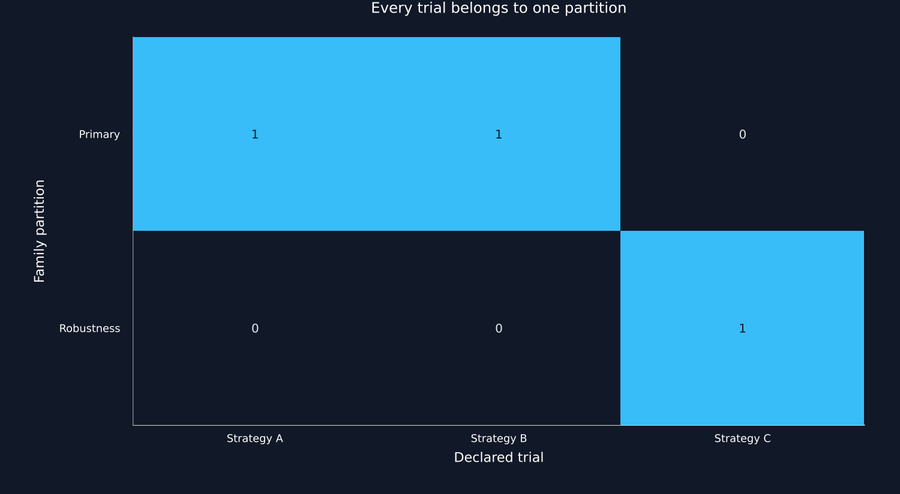

In [1]:
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        end
    end
    caption,label=captions[name]
    save_table(shown,paths,name;caption=caption,label=label)
    return nothing
end
dates,industry_names,industry_returns=protocol_returns()
observation_ids=Tuple("event-".*string.(dates[1:6]))
report=validate_causal_factor_protocol(valid_protocol_report(observation_ids))
multiple_testing=report.multiple_testing_adjustments
trial_labels=Dict(value=>"Strategy "*uppercase(last(value,1)) for value in report.declared_trial_ids)
family_table=frame(["Stage","Family","Declared trials","Trial count"],[(name,stage.trial_family_id,join([trial_labels[value] for value in stage.declared_trial_ids],", "),length(stage.declared_trial_ids)) for (name,stage) in [("Stage 6 backtest",report.backtest),("Stage 7 adjustment",multiple_testing)]])
table(family_table,"protocol_trial_family_identity")
partition_table=frame(["Partition","Trials","Trial count"],[(titlecase(partition),join([trial_labels[value] for value in ids],", "),length(ids)) for (partition,ids) in multiple_testing.family_partitions])
table(partition_table,"protocol_family_partitions")
partition_names=[titlecase(value[1]) for value in multiple_testing.family_partitions]
partition_matrix=[Int(trial in ids) for (name,ids) in multiple_testing.family_partitions,trial in report.declared_trial_ids]
trial_names=[trial_labels[value] for value in report.declared_trial_ids]
partition_frame=hcat(DataFrame("Partition"=>partition_names),DataFrame(partition_matrix,trial_names))
table(partition_frame,"protocol_partition_membership")
figure=heatmap_record(partition_matrix,trial_names,partition_names;title="Every trial belongs to one partition",xlabel="Declared trial",ylabel="Family partition")
save_figure(figure,paths,"protocol_partition_membership")


## Constructing a complete family partition

The partitions must cover the declared family exactly and may not overlap:

$$
\bigcup_{g=1}^{G}\mathcal F_g=\mathcal F,
\qquad
\mathcal F_g\cap\mathcal F_h=\varnothing\quad(g\ne h).
$$

Here, $\mathcal F$ is the complete family of declared trials; $\mathcal F_g$ and $\mathcal F_h$ are two named partitions; $G$ is the number of partitions; the union condition requires complete coverage; and the intersection condition requires disjoint membership.

Row,Case,Stage,Result,Message,Rejected
,String,String,String,Abstract…,String
1,Exact declared partition,Stage 7,Accepted,Record satisfies the released checks,No
2,One trial omitted,Stage 7,Rejected,Stage 7: family partitions must cover declared trials exactly,Yes
3,One trial repeated,Stage 7,Rejected,Stage 7: family partitions must be disjoint,Yes
4,Unknown trial added,Stage 7,Rejected,Stage 7: family partitions must cover declared trials exactly,Yes
5,Partition name repeated,Stage 7,Rejected,Stage 7: family partition identifiers must be unique,Yes


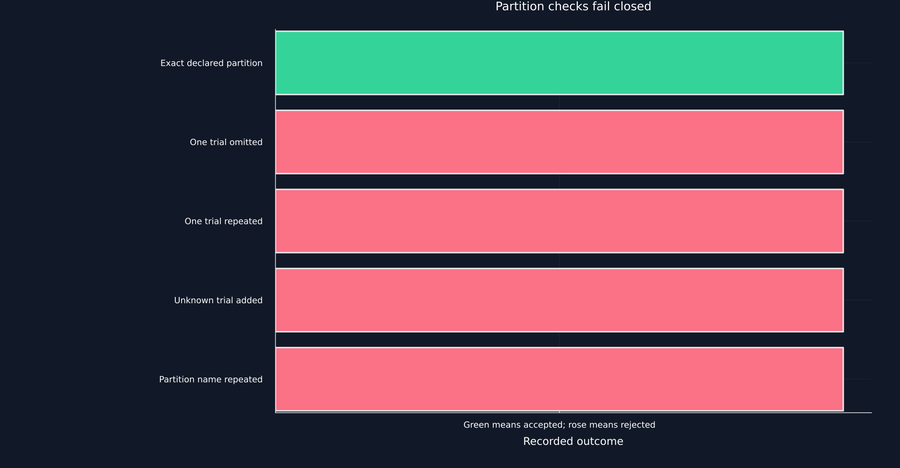

In [2]:
partition_variants=[("Exact declared partition",multiple_testing.family_partitions),("One trial omitted",(("primary",("strategy-a","strategy-b")),)),("One trial repeated",(("primary",("strategy-a","strategy-b")),("robustness",("strategy-b","strategy-c")))),("Unknown trial added",(("primary",("strategy-a","strategy-b")),("robustness",("strategy-c","strategy-d")))),("Partition name repeated",(("primary",("strategy-a","strategy-b")),("primary",("strategy-c",))))]
partition_checks=case_frame([contract_case(name,"Stage 7",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;family_partitions=partitions)))) for (name,partitions) in partition_variants])
table(partition_checks,"protocol_partition_checks")
figure=colored_bars(1:nrow(partition_checks),ones(nrow(partition_checks)),ifelse.(partition_checks.Rejected,palette.rose,palette.green);orientation=:horizontal,yticks=(1:nrow(partition_checks),partition_checks.Case),yflip=true,label="",xlims=(0,1.05),xticks=([.5],["Green means accepted; rose means rejected"]),xlabel="Recorded outcome",title="Partition checks fail closed",size=(1250,650),left_margin=55Plots.mm)
save_figure(figure,paths,"protocol_partition_checks")


## Public-Return P Values

A long-run variance estimate can allow for serial dependence in a return path:

$$
\widehat{\Omega}
=
\widehat{\gamma}_0+
2\sum_{k=1}^{L}
\left(1-\frac{k}{L+1}\right)\widehat{\gamma}_k.
$$

Here, $\widehat{\Omega}$ is the estimated long-run variance; $\widehat{\gamma}_0$ is the return variance; $\widehat{\gamma}_k$ is the lag-$k$ covariance; $L$ is the chosen lag limit; and the declining factor gives less weight to longer lags.

In [3]:
trial_dates,trial_returns=public_trial_returns(dates,industry_returns)
p_value_rows=[]
covariance_rows=[]
for (name,values) in zip(trial_names,eachcol(trial_returns))
    probability,statistic,lag_limit,variance=dependence_adjusted_p_value(values)
    push!(p_value_rows,(name,length(values),mean(values),statistic,probability,lag_limit,variance))
    centered=values.-mean(values)
    for lag in 0:lag_limit
        covariance=dot(centered[lag+1:end],centered[1:end-lag])/length(values)
        push!(covariance_rows,(name,lag,covariance))
    end
end
p_value_table=frame(["Declared trial","Observations","Mean daily return","Dependence-adjusted statistic","Raw p value","Lag limit","Long-run variance"],p_value_rows)
table(p_value_table,"protocol_public_p_values")
save_data(frame(["Declared trial","Lag","Autocovariance"],covariance_rows),paths,"protocol_trial_autocovariances")
nothing


Row,Declared trial,Observations,Mean daily return,Dependence-adjusted statistic,Raw p value,Lag limit,Long-run variance
,String,Int64,Float64,Float64,Float64,Int64,Float64
1,Strategy A,752,0.000338298,1.24583,0.212826,6,5.54495e-5
2,Strategy B,752,-0.000152194,-0.580084,0.561858,6,5.17645e-5
3,Strategy C,752,0.000152194,0.580084,0.561858,6,5.17645e-5


## Comparing two multiple-testing corrections

Holm's adjusted value for the $i$th ordered raw value is:

$$
\widetilde p_{(i)}^{\mathrm H}
=
\max_{1\le j\le i}
\min\!\left\{1,(m-j+1)p_{(j)}\right\}.
$$

Here, $p_{(j)}$ is the $j$th smallest raw p value; $m$ is the number of declared trials; $i$ is an ordered position; and $\widetilde p_{(i)}^{\mathrm H}$ is the Holm-adjusted value after enforcing a nondecreasing sequence.

The Benjamini-Hochberg adjusted value works backward through the ordered raw values:

$$
\widetilde p_{(i)}^{\mathrm{BH}}
=
\min_{i\le j\le m}
\min\!\left\{1,\frac{m}{j}p_{(j)}\right\}.
$$

Here, $p_{(j)}$ is the $j$th smallest raw p value; $m$ is the number of declared trials; $j$ is an ordered position at or above $i$; and $\widetilde p_{(i)}^{\mathrm{BH}}$ is the Benjamini-Hochberg adjusted value after enforcing a nondecreasing sequence.

Row,Declared trial,Raw p value,Holm adjusted p value,Benjamini-Hochberg adjusted p value,Holm rejects at five percent,Benjamini-Hochberg rejects at five percent
,String,Float64,Float64,Float64,String,String
1,Strategy A,0.212826,0.638478,0.561858,No,No
2,Strategy B,0.561858,1.0,0.561858,No,No
3,Strategy C,0.561858,1.0,0.561858,No,No


Row,Method,Role in this notebook,Error target
,String,String,String
1,Holm,Calculated for the public-return family,Probability of at least one false rejection
2,Benjamini-Hochberg,Calculated for comparison,Expected false share among rejections
3,Hochberg,Listed as a Stage 7 choice; no separate calculation here,Probability of at least one false rejection
4,Deflated Sharpe ratio,Calculated from declared selection inputs,Selection bias in the reported Sharpe ratio


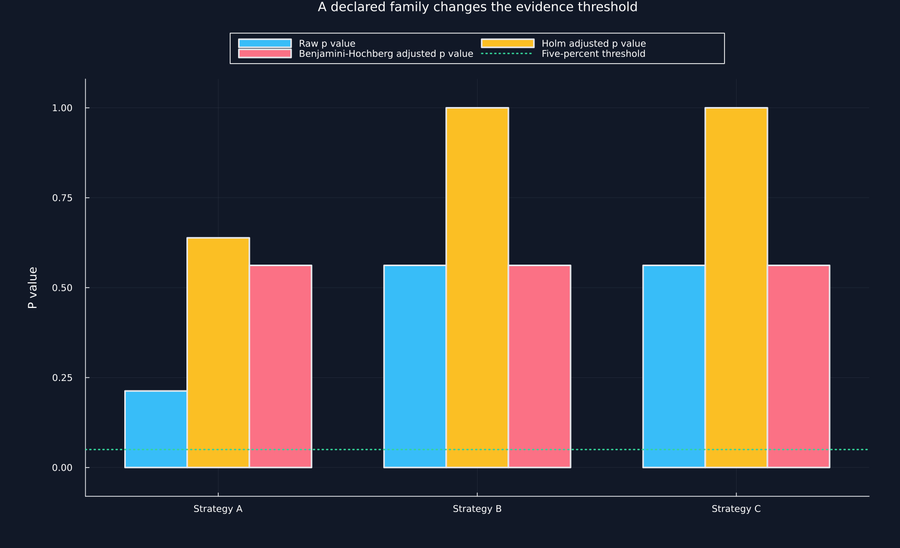

In [4]:
raw_p_values=p_value_table[:,"Raw p value"]
adjustment_table=p_value_table[:,["Declared trial","Raw p value"]]
adjustment_table[!,"Holm adjusted p value"]=holm_adjusted(raw_p_values)
adjustment_table[!,"Benjamini-Hochberg adjusted p value"]=benjamini_hochberg_adjusted(raw_p_values)
adjustment_table[!,"Holm rejects at five percent"]=adjustment_table[:,"Holm adjusted p value"].<=multiple_testing.alpha
adjustment_table[!,"Benjamini-Hochberg rejects at five percent"]=adjustment_table[:,"Benjamini-Hochberg adjusted p value"].<=multiple_testing.alpha
table(adjustment_table,"protocol_public_adjustments")
method_scope=frame(["Method","Role in this notebook","Error target"],[["Holm","Calculated for the public-return family","Probability of at least one false rejection"],["Benjamini-Hochberg","Calculated for comparison","Expected false share among rejections"],["Hochberg","Listed as a Stage 7 choice; no separate calculation here","Probability of at least one false rejection"],["Deflated Sharpe ratio","Calculated from declared selection inputs","Selection bias in the reported Sharpe ratio"]])
table(method_scope,"protocol_adjustment_scope")
figure=plot(;xticks=(1:3,trial_names),ylabel="P value",title="A declared family changes the evidence threshold",legend=:outertop,legend_columns=2,size=(1150,700))
for (offset,column,color) in [(-.24,"Raw p value",palette.cyan),(0.,"Holm adjusted p value",palette.amber),(.24,"Benjamini-Hochberg adjusted p value",palette.rose)]
    bar!(figure,(1:3).+offset,adjustment_table[:,column];bar_width=.24,color=color,label=column)
end
hline!(figure,[multiple_testing.alpha];color=palette.green,linestyle=:dot,linewidth=1.8,label="Five-percent threshold")
bar_headroom!(figure,vcat(vec(Matrix(adjustment_table[:,2:4])),multiple_testing.alpha))
save_figure(figure,paths,"protocol_public_adjustments")


## Deflated Sharpe Evidence

A trial-count benchmark for the largest Sharpe ratio can be approximated by:

$$
\widehat{SR}^{\,*}
=
\sqrt{\widehat V_{SR}}
\left[
(1-\gamma)\Phi^{-1}\!\left(1-\frac{1}{N_{\mathrm{eff}}}\right)
+
\gamma\Phi^{-1}\!\left(1-\frac{1}{eN_{\mathrm{eff}}}\right)
\right].
$$

Here, $\widehat{SR}^{\,*}$ is the selection benchmark; $\widehat V_{SR}$ is the declared variance across Sharpe estimates; $\gamma$ is the Euler constant; $\Phi^{-1}$ is the standard-normal quantile; $N_{\mathrm{eff}}$ is the effective number of trials; and $e$ is the base of the natural logarithm.

The probability that an observed Sharpe ratio exceeds that benchmark is:

$$
\operatorname{PSR}(\widehat{SR}^{\,*})
=
\Phi\!\left(
\frac{(\widehat{SR}-\widehat{SR}^{\,*})\sqrt{T-1}}
{\sqrt{1-\widehat\gamma_3\widehat{SR}+\frac{\widehat\gamma_4-1}{4}\widehat{SR}^{\,2}}}
\right).
$$

Here, $\operatorname{PSR}$ is the probabilistic Sharpe value; $\widehat{SR}$ is the observed Sharpe ratio; $\widehat{SR}^{\,*}$ is the selection benchmark; $T$ is the sample length; $\widehat\gamma_3$ is sample skewness; $\widehat\gamma_4$ is sample Pearson kurtosis; and $\Phi$ is the standard-normal cumulative distribution function.

Row,Input,Value,Role
,String,Real,String
1,Variance across Sharpe estimates,0.04,Scale of the selection benchmark
2,Effective trials,2.0,Independent-equivalent search count
3,Total declared trials,3,Upper bound for effective trials
4,Sample length,252,Precision of the observed Sharpe ratio
5,Skewness,0.1,Asymmetry adjustment
6,Pearson kurtosis,3.2,Tail-shape adjustment


Row,Effective trials,Selection benchmark,Probability above benchmark,Record accepted
,Float64,Float64,Float64,String
1,1.01,-0.156947,0.999999,Yes
2,1.25,-0.00872679,0.994099,Yes
3,1.5,0.0431776,0.954925,Yes
4,2.0,0.103951,0.767461,Yes
5,2.5,0.142491,0.547413,Yes
6,2.99,0.170069,0.375102,Yes


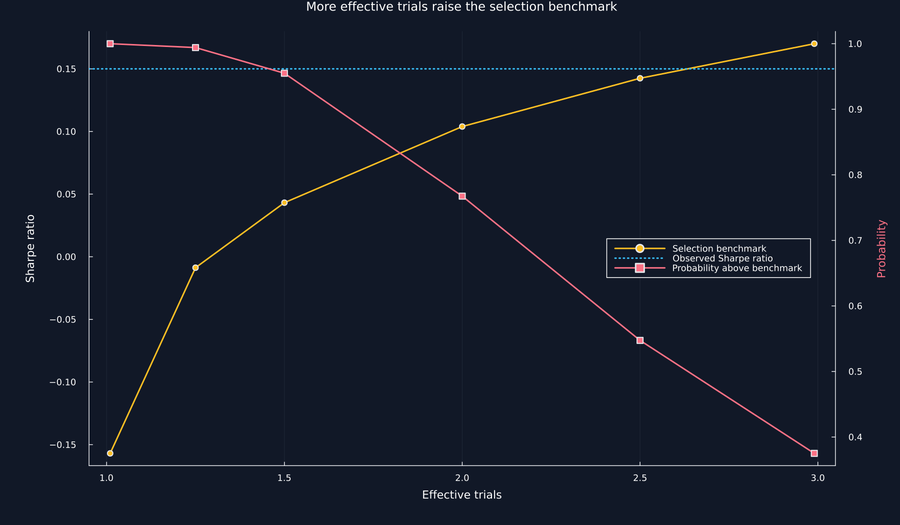

In [5]:
dsr_inputs=frame(["Input","Value","Role"],[("Variance across Sharpe estimates",multiple_testing.sharpe_variance,"Scale of the selection benchmark"),("Effective trials",multiple_testing.effective_trials,"Independent-equivalent search count"),("Total declared trials",length(multiple_testing.declared_trial_ids),"Upper bound for effective trials"),("Sample length",multiple_testing.sample_length,"Precision of the observed Sharpe ratio"),("Skewness",multiple_testing.skewness,"Asymmetry adjustment"),("Pearson kurtosis",multiple_testing.kurtosis,"Tail-shape adjustment")])
table(dsr_inputs,"protocol_dsr_inputs")
observed_sharpe=.15
effective_grid=[1.01,1.25,1.5,2.,2.5,2.99]
sensitivity_rows=[]
for count in effective_grid
    benchmark=expected_maximum_sharpe(multiple_testing.sharpe_variance,count)
    probability=probabilistic_sharpe(observed_sharpe,benchmark,multiple_testing.sample_length,multiple_testing.skewness,multiple_testing.kurtosis)
    accepted=validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;effective_trials=count)))
    push!(sensitivity_rows,(count,benchmark,probability,accepted isa CausalFactorProtocolReport))
end
dsr_sensitivity=frame(["Effective trials","Selection benchmark","Probability above benchmark","Record accepted"],sensitivity_rows)
table(dsr_sensitivity,"protocol_dsr_sensitivity")
figure=plot(effective_grid,dsr_sensitivity[:,2];color=palette.amber,marker=:circle,label="Selection benchmark",xlabel="Effective trials",ylabel="Sharpe ratio",title="More effective trials raise the selection benchmark",legend=:right,size=(1200,700))
hline!(figure,[observed_sharpe];color=palette.cyan,linestyle=:dot,label="Observed Sharpe ratio")
plot!(figure,[NaN],[NaN];color=palette.rose,marker=:square,label="Probability above benchmark")
right=twinx(figure)
plot!(right,effective_grid,dsr_sensitivity[:,3];color=palette.rose,marker=:square,label="",legend=false,ylabel="Probability",foreground_color_guide=palette.rose)
save_figure(figure,paths,"protocol_dsr_sensitivity")


## Feasible Moment Records

Skewness and Pearson kurtosis must satisfy the moment inequality:

$$
\widehat\gamma_3^{\,2}\le \widehat\gamma_4-1.
$$

Here, $\widehat\gamma_3$ is the declared skewness and $\widehat\gamma_4$ is the declared Pearson kurtosis; the inequality rules out pairs of moments that no probability distribution can have.

Row,Skewness,Pearson kurtosis,Moment inequality holds,Record accepted
,Float64,Float64,String,String
1,-1.5,1.0,No,No
2,-1.0,1.0,No,No
3,-0.5,1.0,No,No
4,0.0,1.0,Yes,Yes
5,0.5,1.0,No,No
6,1.0,1.0,No,No
7,1.5,1.0,No,No
8,-1.5,1.5,No,No
9,-1.0,1.5,No,No


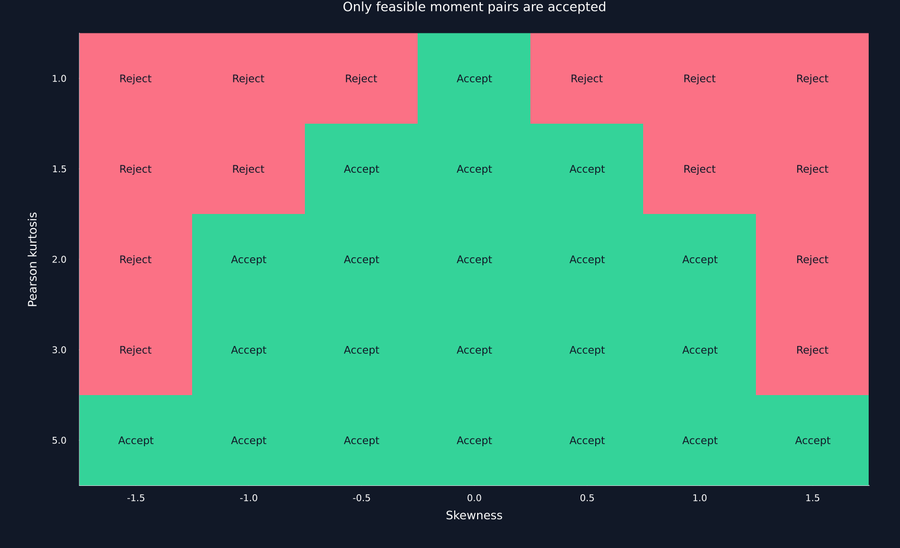

In [6]:
skewness_values=[-1.5,-1.,-.5,0.,.5,1.,1.5]
kurtosis_values=[1.,1.5,2.,3.,5.]
moment_acceptance=zeros(Int,length(kurtosis_values),length(skewness_values))
moment_rows=[]
for (row,kurtosis) in enumerate(kurtosis_values),(column,skewness) in enumerate(skewness_values)
    result=contract_case("Moment pair","Stage 7",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;skewness=skewness,kurtosis=kurtosis))))
    moment_acceptance[row,column]=Int(!result[5])
    push!(moment_rows,(skewness,kurtosis,skewness^2<=kurtosis-1+1e-12,!result[5]))
end
moment_table=frame(["Skewness","Pearson kurtosis","Moment inequality holds","Record accepted"],moment_rows)
table(moment_table,"protocol_moment_grid")
figure=heatmap_record(moment_acceptance,string.(skewness_values),string.(kurtosis_values);title="Only feasible moment pairs are accepted",xlabel="Skewness",ylabel="Pearson kurtosis",colors=[palette.rose,palette.green],labels=ifelse.(moment_acceptance.==1,"Accept","Reject"),size=(1150,700))
save_figure(figure,paths,"protocol_moment_grid")


## Dependence Evidence

The correlation matrix records dependence among the declared public-return paths:

$$
\widehat\rho_{ij}
=
\frac{\sum_{t=1}^{T}(R_{it}-\overline R_i)(R_{jt}-\overline R_j)}
{\sqrt{\sum_{t=1}^{T}(R_{it}-\overline R_i)^2}\sqrt{\sum_{t=1}^{T}(R_{jt}-\overline R_j)^2}}.
$$

Here, $\widehat\rho_{ij}$ is the sample correlation between trials $i$ and $j$; $R_{it}$ and $R_{jt}$ are their returns at time $t$; $\overline R_i$ and $\overline R_j$ are their sample means; and $T$ is the number of public observations.

Row,Requirement,Recorded evidence,Complete
,String,String,String
1,Dependence flag,Backtests are not independent,Yes
2,P-value estimator,estimator accounting for time dependence,Yes
3,Time-dependence treatment,purged temporal folds,Yes
4,Independence assumption in inputs,Explicitly rejected,Yes
5,Selection-bias evidence,selection-bias-evidence,Yes


Row,Declared trial,Strategy A,Strategy B,Strategy C
,String,Float64,Float64,Float64
1,Strategy A,1.0,-0.164445,0.164445
2,Strategy B,-0.164445,1.0,-1.0
3,Strategy C,0.164445,-1.0,1.0


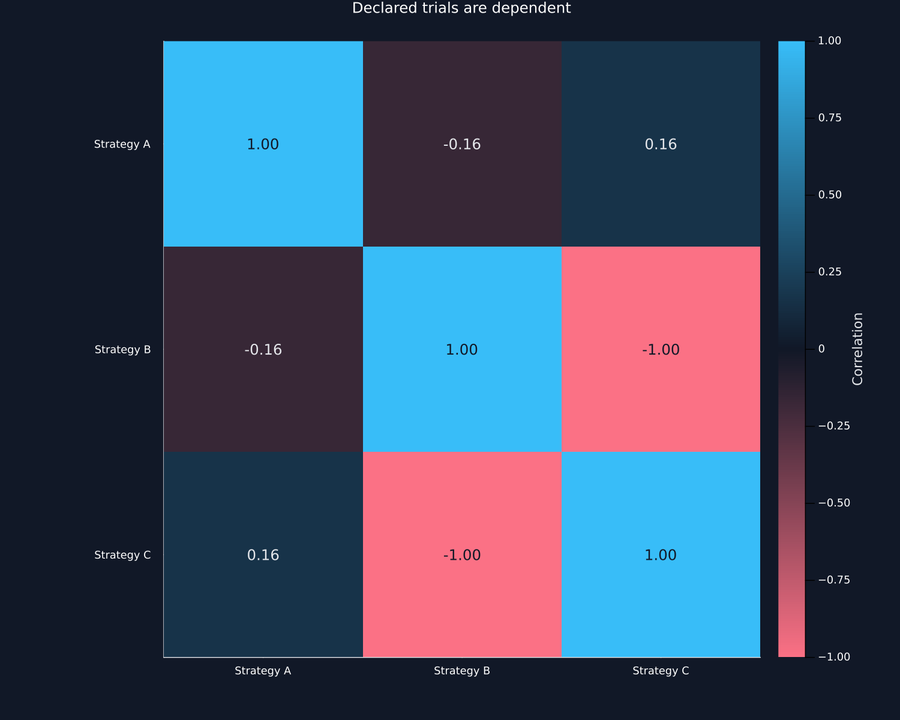

In [7]:
dependence_record=frame(["Requirement","Recorded evidence","Complete"],[("Dependence flag","Backtests are not independent",!multiple_testing.backtests_independent),("P-value estimator",multiple_testing.p_value_estimator,!isempty(multiple_testing.p_value_estimator)),("Time-dependence treatment",multiple_testing.time_dependence_model,!isempty(multiple_testing.time_dependence_model)),("Independence assumption in inputs","Explicitly rejected",multiple_testing.p_value_inputs_assume_independence===false),("Selection-bias evidence",multiple_testing.selection_bias_evidence_id,!isempty(multiple_testing.selection_bias_evidence_id))])
table(dependence_record,"protocol_dependence_record")
correlation=cor(trial_returns)
correlation_table=hcat(DataFrame("Declared trial"=>trial_names),DataFrame(correlation,trial_names))
table(correlation_table,"protocol_trial_correlation")
figure=heatmap(1:3,1:3,correlation;c=cgrad([palette.rose,palette.background,palette.cyan]),clims=(-1,1),yflip=true,xticks=(1:3,trial_names),yticks=(1:3,trial_names),title="Declared trials are dependent",colorbar_title="Correlation",grid=false,size=(1000,800),left_margin=25Plots.mm)
for row in 1:3,column in 1:3
    annotate!(figure,column,row,text(@sprintf("%.2f",correlation[row,column]),11,abs(correlation[row,column])>.5 ? palette.background : palette.text,:center))
end
save_figure(figure,paths,"protocol_trial_correlation")


## Checking released results against immutable records

In [8]:
records=[report.variable_selection,report.causal_discovery,report.causal_adjustment_set,report.causal_explanatory_and_predictive_power,report.causal_portfolio_construction,report.backtest,report.multiple_testing_adjustments,report]
record_rows=[]
for value in records
    field=first(fieldnames(typeof(value)))
    frozen=try
        setfield!(value,field,getfield(value,field))
        false
    catch
        !ismutable(value)
    end
    count=sum(getfield(value,name) isa Tuple for name in fieldnames(typeof(value)))
    push!(record_rows,(replace(record_name(value)," Stage"=>""),frozen,count,frozen&&count>0))
end
record_table=frame(["Evidence record","Frozen","Tuple fields","Passed"],record_rows)
table(record_table,"protocol_record_checks")
public_names=[EventHorizon,FoldEvidence,ValidationEvidence,VariableSelectionStage,CausalDiscoveryStage,CausalAdjustmentSetStage,CausalExplanatoryAndPredictivePowerStage,CausalPortfolioConstructionStage,BacktestStage,MultipleTestingAdjustmentsStage,CausalFactorProtocolReport,validate_causal_factor_protocol]
public_name_table=frame(["Released name","Kind","Covered here"],[(strip(replace(replace(string(nameof(value)),r"(?<!^)(?=[A-Z])"=>" "),"_"=>" ")),value isa Function ? "Check" : "Evidence record","Yes") for value in public_names])
table(public_name_table,"protocol_public_names")


Row,Evidence record,Frozen,Tuple fields,Passed
,String,String,Int64,String
1,Variable Selection,Yes,2,Yes
2,Causal Discovery,Yes,5,Yes
3,Causal Adjustment Set,Yes,9,Yes
4,Causal Explanatory And Predictive Power,Yes,3,Yes
5,Causal Portfolio Construction,Yes,4,Yes
6,Backtest,Yes,2,Yes
7,Multiple Testing Adjustments,Yes,3,Yes
8,Causal Factor Protocol Report,Yes,1,Yes


Row,Released name,Kind,Covered here
,SubStrin…,String,String
1,Event Horizon,Evidence record,Yes
2,Fold Evidence,Evidence record,Yes
3,Validation Evidence,Evidence record,Yes
4,Variable Selection Stage,Evidence record,Yes
5,Causal Discovery Stage,Evidence record,Yes
6,Causal Adjustment Set Stage,Evidence record,Yes
7,Causal Explanatory And Predictive Power Stage,Evidence record,Yes
8,Causal Portfolio Construction Stage,Evidence record,Yes
9,Backtest Stage,Evidence record,Yes


## Rejected Stage 7 Evidence

Row,Case,Stage,Result,Message,Rejected
,String,String,String,SubStrin…,String
1,Trial family differs from the report,Stage 7,Rejected,Stage 7: trial-family identifier must match the report,Yes
2,Declared trials differ from the report,Stage 7,Rejected,Stage 7: declared trials must match the report exactly,Yes
3,Partition coverage is incomplete,Stage 7,Rejected,Stage 7: family partitions must cover declared trials exactly,Yes
4,Partitions overlap,Stage 7,Rejected,Stage 7: family partitions must be disjoint,Yes
5,Significance level equals zero,Stage 7,Rejected,Stage 7: alpha must be a finite number between zero and one,Yes
6,Significance level equals one,Stage 7,Rejected,Stage 7: alpha must be a finite number between zero and one,Yes
7,Independence is asserted,Stage 7,Rejected,Stage 7: backtest dependence must be represented,Yes
8,P-value estimator is missing,Stage 7,Rejected,Stage 7: p-value estimator must be declared,Yes
9,Time treatment is missing,Stage 7,Rejected,Stage 7: time dependence treatment must be declared,Yes


Row,Evidence group,Rejected cases
,String,Int64
1,Family identity and coverage,4
2,Decision threshold and dependence,6
3,Deflated Sharpe inputs,4


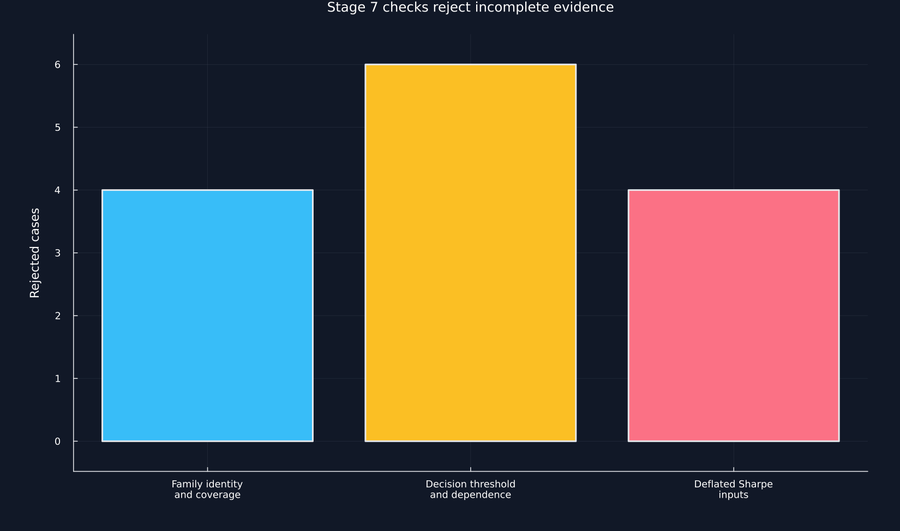

Row,Question,Evidence
,String,String
1,Was one complete family declared before correction?,Matching family and trial identifiers in Stages 6 and 7
2,Do named partitions cover the family once?,Complete and disjoint partition records
3,Does the correction recognize time dependence?,A declared estimator and time-dependence treatment
4,Are selection inputs feasible and complete?,"Trial count, variance, sample length, moments, and selection record"
5,Can a partial record pass?,No; incomplete records are rejected


In [9]:
rejection_cases=[("Trial family differs from the report",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;trial_family_id="different-family")))),("Declared trials differ from the report",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;declared_trial_ids=("strategy-a","strategy-b"))))),("Partition coverage is incomplete",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;family_partitions=(("primary",("strategy-a","strategy-b")),))))),("Partitions overlap",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;family_partitions=(("primary",("strategy-a","strategy-b")),("robustness",("strategy-b","strategy-c"))))))),("Significance level equals zero",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;alpha=0.0)))),("Significance level equals one",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;alpha=1.0)))),("Independence is asserted",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;backtests_independent=true)))),("P-value estimator is missing",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;p_value_estimator="")))),("Time treatment is missing",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;time_dependence_model="")))),("P-value inputs assume independence",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;p_value_inputs_assume_independence=true)))),("Effective trials equal total trials",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;effective_trials=3.0)))),("Pearson kurtosis is below one",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;kurtosis=0.5)))),("Moment inequality is violated",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;skewness=2.0,kurtosis=3.0)))),("Selection-bias evidence is missing",()->validate_causal_factor_protocol(update_record(report;multiple_testing_adjustments=update_record(multiple_testing;selection_bias_evidence_id=""))))]
rejection_table=case_frame([contract_case(name,"Stage 7",action) for (name,action) in rejection_cases])
table(rejection_table,"protocol_stage7_rejections")
rejection_groups=frame(["Evidence group","Rejected cases"],[["Family identity and coverage",4],["Decision threshold and dependence",6],["Deflated Sharpe inputs",4]])
table(rejection_groups,"protocol_stage7_rejection_groups")
figure=colored_bars(1:3,rejection_groups[:,2],[palette.cyan,palette.amber,palette.rose];xticks=(1:3,["Family identity\nand coverage","Decision threshold\nand dependence","Deflated Sharpe\ninputs"]),label="",ylabel="Rejected cases",title="Stage 7 checks reject incomplete evidence",size=(1100,650))
bar_headroom!(figure,rejection_groups[:,2])
save_figure(figure,paths,"protocol_stage7_rejections")
section_summary=frame(["Question","Evidence"],[["Was one complete family declared before correction?","Matching family and trial identifiers in Stages 6 and 7"],["Do named partitions cover the family once?","Complete and disjoint partition records"],["Does the correction recognize time dependence?","A declared estimator and time-dependence treatment"],["Are selection inputs feasible and complete?","Trial count, variance, sample length, moments, and selection record"],["Can a partial record pass?","No; incomplete records are rejected"]])
table(section_summary,"protocol_section3_summary")


## Tests

In [10]:
@assert report.backtest.trial_family_id==multiple_testing.trial_family_id
@assert report.backtest.declared_trial_ids==multiple_testing.declared_trial_ids
@assert all(sum(partition_matrix;dims=1).==1)
@assert !only(partition_checks[partition_checks.Case.=="Exact declared partition",:Rejected])
@assert all(partition_checks[partition_checks.Case.!="Exact declared partition",:Rejected])
@assert all(0 .<=p_value_table[:,"Raw p value"].<=1)
@assert all(0 .<=Matrix(adjustment_table[:,3:4]).<=1)
@assert all(adjustment_table[:,3] .+ 1e-15 .>=raw_p_values)
@assert all(adjustment_table[:,4] .+ 1e-15 .>=raw_p_values)
@assert all(dsr_sensitivity[:,"Record accepted"])
@assert issorted(dsr_sensitivity[:,"Selection benchmark"])
@assert issorted(dsr_sensitivity[:,"Probability above benchmark"];rev=true)
@assert moment_table[:,"Moment inequality holds"]==moment_table[:,"Record accepted"]
@assert all(dependence_record.Complete)
@assert all(isapprox.(diag(correlation),1.))
@assert all(record_table.Passed)
@assert nrow(public_name_table)==12
@assert all(rejection_table.Rejected)
@assert sum(rejection_groups[:,2])==nrow(rejection_table)
for name in ["protocol_partition_membership","protocol_partition_checks","protocol_public_adjustments","protocol_dsr_sensitivity","protocol_moment_grid","protocol_trial_correlation","protocol_stage7_rejections"]
    @assert isfile(joinpath(paths.figures,name*".pdf"))
end
for name in ["protocol_trial_family_identity","protocol_family_partitions","protocol_partition_membership","protocol_partition_checks","protocol_public_p_values","protocol_public_adjustments","protocol_adjustment_scope","protocol_dsr_inputs","protocol_dsr_sensitivity","protocol_moment_grid","protocol_dependence_record","protocol_trial_correlation","protocol_record_checks","protocol_public_names","protocol_stage7_rejections","protocol_stage7_rejection_groups","protocol_section3_summary"]
    @assert isfile(joinpath(paths.tables,name*".tex"))
end
